# A decoder written in Python, compiled with numba

A decoder is the local model an ensemble applies inside each cell of each partition. Besides the decoders Spatialize ships, we can add our own in a few Python functions, without compiling anything. Here we build a
decoder for terrain, check it against known answers, avoid the trap its cross-validation sets, speed it
up with numba and compare it with the best built-in decoder on a real elevation model.

## Learning goals

- Which functions make a decoder, and what each receives and returns.
- How to check a new decoder, against a built-in one and on a field whose answer we know.
- Why a fit stored per cell makes the derived leave-one-out optimistic, and how to write your own.
- How much numba speeds up a decoder that loops over its data.
- How to choose `alpha` for the new decoder with the Pareto search and judge it against adaptive IDW.

*How do we add a local model of our own to an ensemble, and know that it works?*

## The idea

An ensemble predicts a location from many partitions of the plane. In each partition, the cell that
holds the location sends its data to the decoder, which returns a prediction. The ensemble collects one
prediction per partition and aggregates them. The decoder never sees the partition. It sees the data of
one cell and the locations to predict in it, so any local model fits this mould.

`local_interpolator="custom"` takes up to four functions.

- `estimation(points, values, queries, params)` predicts the `queries` of one cell from its data.
- `post_creation(points, values)` computes, once per cell, an array of parameters that the other
  functions receive as `params`.
- `loo(points, values, params)` predicts each datum of the cell from the others.
- `kfold(k, points, values, folds, params)` does the same by folds.

Only `estimation` is required. Without `loo` and `kfold`, Spatialize derives them by calling
`estimation` without the held-out data, reusing `params`.

Terrain suggests a decoder. Over a few kilometres a hillside is close to a plane, while the relief
departs from it in ridges and gullies. A plane fitted in each cell captures the slope, and inverse
distance weighting of the residuals restores the relief at the data. The developer guide's page
[Writing a decoder in Python](https://spatialize.readthedocs.io/en/latest/development/python_decoders.html)
lists every rule of the functions.

## Step by step

### The elevation of Walker Lake

The data are 780 samples of the elevation of the Walker Lake area in Nevada, a 26 km × 30 km window
whose whole elevation model we know. It holds the flat surface of the lake, the steep Wassuk Range to
the west and lower hills to the east.

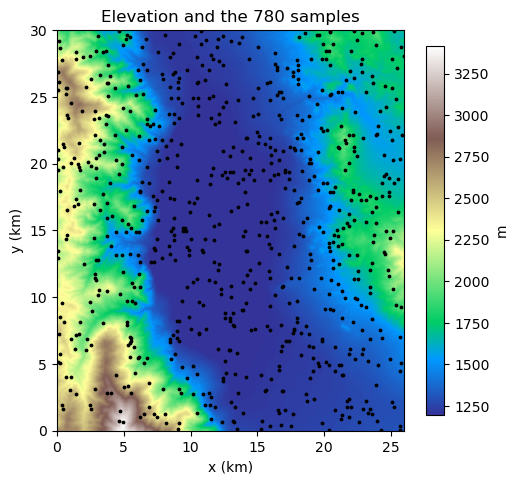

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

import spatialize
from spatialize.data import load_elevation_walker_lake
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.scoring as sc

spatialize.session.set(empty_cells="coarsen", progress=False)

samples, grid = load_elevation_walker_lake()
points, values = samples[["x", "y"]].values, samples["elevation"].values
xi, truth = grid[["x", "y"]].values, grid["elevation"].values
shape, extent = (300, 260), (0, 26, 0, 30)          # the grid runs along x first

fig, ax = plt.subplots(figsize=(5.6, 6))
im = ax.imshow(truth.reshape(shape), origin="lower", extent=extent, cmap="terrain")
ax.scatter(points[:, 0], points[:, 1], s=3, c="black")
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_title("Elevation and the 780 samples")
fig.colorbar(im, ax=ax, shrink=0.8, label="m")
plt.show()

### A first decoder

The simplest decoder predicts every location of a cell with the mean of its data. Spatialize has it
built in as `cellmean`, so we can compare the two. The functions receive NumPy arrays of float32.

In [2]:
def cell_mean(points, values, queries, params):
    return np.full(len(queries), values.mean())

common = dict(n_partitions=50, alpha=0.8, seed=0)
ours = esi_nongriddata(points, values, xi, local_interpolator="custom", estimation=cell_mean, **common)
builtin = esi_nongriddata(points, values, xi, local_interpolator="cellmean", **common)
difference = np.abs(ours.esi_samples(raw=True) - builtin.esi_samples(raw=True))
print(f"largest difference between the members {difference.max():.1e} m")

largest difference between the members 4.9e-04 m


The members agree to a fraction of a millimetre, the rounding of float32 at elevations of a few
thousand metres. Both decoders see the same cells, which confirms that the partitions do not depend on
the decoder.

### A plane in each cell

A plane is fitted once per cell, so it belongs in `post_creation`. Its parameters must be numbers in a
one-dimensional array, here the centre of the data, the value of the plane there, its slope along each
axis and a flag that says whether a plane was fitted. With fewer than six data, or with data nearly on
a line, the slope across the cell is undetermined, so the decoder falls back to the mean of the cell.
`estimation` then only evaluates the plane.

Both functions are compiled with numba's `@njit`, which needs explicit types. The coordinates arrive
as float32, so we convert them to float64 before any matrix product.

In [3]:
@njit(cache=True)
def plane_fit(points, values):
    # [centre (d values), value at the centre, slope along each axis (d values), 1 if fitted]
    m, d = points.shape
    out = np.zeros(2 * d + 2)
    for j in range(d):
        out[j] = points[:, j].mean()
    out[d] = values.mean()
    if m < 2 * (d + 1):
        return out
    centred = np.empty((m, d))
    for j in range(d):
        centred[:, j] = points[:, j] - out[j]
    spread = np.linalg.eigvalsh(centred.T @ centred)
    if spread[0] < 0.01 * spread[-1]:            # nearly on a line
        return out
    design = np.ones((m, d + 1))
    design[:, 1:] = centred
    out[d:2 * d + 1] = np.linalg.lstsq(design, values.astype(np.float64))[0]
    out[2 * d + 1] = 1.0
    return out

@njit(cache=True)
def plane_at(params, queries, d):
    out = np.empty(queries.shape[0])
    for i in range(queries.shape[0]):
        z = params[d]
        for j in range(d):
            z += params[d + 1 + j] * (queries[i, j] - params[j])
        out[i] = z
    return out

@njit(cache=True)
def plane_estimation(points, values, queries, params):
    return plane_at(params.astype(np.float64), queries, points.shape[1])

### Checking on a known answer

On a field that is exactly a plane, every member computed from a fitted plane must reproduce the
field. A strict version of the decoder returns NaN where it fell back to the mean, so the members left
are those of fitted planes.

In [4]:
@njit(cache=True)
def plane_strict(points, values, queries, params):
    if params[-1] == 0.0:
        return np.full(queries.shape[0], np.nan)
    return plane_at(params.astype(np.float64), queries, points.shape[1])

tilted = 1200.0 + 40.0 * points[:, 0] - 15.0 * points[:, 1]
exact = 1200.0 + 40.0 * xi[:, 0] - 15.0 * xi[:, 1]
with spatialize.session.override(empty_cells="nan"):
    strict = esi_nongriddata(points, tilted, xi, local_interpolator="custom", estimation=plane_strict,
                             post_creation=plane_fit, **common).esi_samples(raw=True)
fitted = ~np.isnan(strict)
print(f"members from a fitted plane {fitted.mean():.1%}, "
      f"largest error among them {np.abs(strict - exact[:, None])[fitted].max():.2e} m")

members from a fitted plane 96.0%, largest error among them 2.44e-04 m


Most members come from a fitted plane, all of them reproducing the tilted field to float32 rounding. The
rest come from cells too small or too thin for a plane, where the decoder takes the mean by design.

### Leave-one-out without the trap

The Pareto search and the other searches score a decoder by predicting each datum from the others.
Without our own `loo`, Spatialize removes the datum and calls `estimation` again, with the `params`
computed on the whole cell. Our `estimation` only evaluates the plane stored in `params`, a plane that
was fitted with the datum it now predicts. The derived leave-one-out then judges the decoder on data it
has already seen.

Our own `loo` refits the plane without each datum. It is a loop of small fits, which numba compiles.

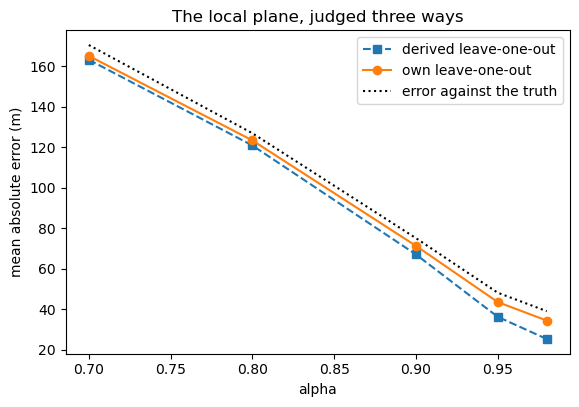

,derived leave-one-out,own leave-one-out,error against the truth
alpha,,,
0.70,163.3,165.2,170.5
0.80,120.9,123.4,127.0
0.90,67.1,71.4,75.2
0.95,36.3,43.6,48.2
0.98,25.3,34.5,39.1


In [5]:
@njit(cache=True)
def plane_loo(points, values, params):
    m, d = points.shape
    out = np.full(m, np.nan)
    for i in range(m):
        if m == 1:
            break
        keep = np.ones(m, dtype=np.bool_)
        keep[i] = False
        refit = plane_fit(points[keep], values[keep])
        out[i] = plane_at(refit, points[i:i + 1], d)[0]
    return out

alphas = [0.7, 0.8, 0.9, 0.95, 0.98]
plane = dict(local_interpolator="custom", estimation=plane_estimation, post_creation=plane_fit)
search_kw = dict(n_partitions=[100], alpha=alphas, k="loo", scoring=sc.mae, seed=0)
derived = esi_pareto_hparams_search(points, values, **plane, **search_kw)
honest = esi_pareto_hparams_search(points, values, **plane, loo=plane_loo, **search_kw)

rows = {}
for alpha, r_derived, r_honest in zip(alphas, derived.all_results, honest.all_results):
    estimate = esi_nongriddata(points, values, xi, **plane, n_partitions=100, alpha=alpha, seed=0).estimation()
    rows[alpha] = {"derived leave-one-out": r_derived["decoder_error"], "own leave-one-out": r_honest["decoder_error"],
                   "error against the truth": np.mean(np.abs(estimate - truth))}
loo_table = pd.DataFrame(rows).T
loo_table.index.name = "alpha"

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for column, style in zip(loo_table.columns, ("s--", "o-", "k:")):
    ax.plot(loo_table.index, loo_table[column], style, label=column)
ax.set_xlabel("alpha"); ax.set_ylabel("mean absolute error (m)")
ax.set_title("The local plane, judged three ways")
ax.legend()
plt.show()
loo_table.round(1)

Our own leave-one-out follows the error against the truth at every `alpha`. The derived one agrees
with it while the cells are large, then drops below it as the cells shrink, since a plane fitted on a
few data passes close to each of them. A search scored by the derived error would credit the fine
partitions with an accuracy they do not have.

### Restoring the relief

A plane leaves the ridges and gullies out. The second decoder adds to the plane an inverse distance
weighting of the residuals, the departures of the data from the plane, which makes it exact at the data.
This time `estimation` fits the plane itself on the data it receives, so the derived leave-one-out
refits without the held-out datum and stays honest. No `post_creation` and no `loo` are needed.

The residual weighting loops over every pair of query and datum. We write it twice, in plain NumPy and
compiled with numba, to see what compiling gains.

In [6]:
@njit(cache=True)
def plane_idw(points, values, queries, params):
    m, d = points.shape
    fit = plane_fit(points, values)
    trend = plane_at(fit, points, d)
    out = plane_at(fit, queries, d)
    for i in range(queries.shape[0]):
        weights, weighted, on_datum = 0.0, 0.0, -1
        for j in range(m):
            d2 = 0.0
            for c in range(d):
                diff = points[j, c] - queries[i, c]
                d2 += diff * diff
            if d2 == 0.0:
                on_datum = j
                break
            weights += 1.0 / d2
            weighted += (values[j] - trend[j]) / d2
        out[i] += values[on_datum] - trend[on_datum] if on_datum >= 0 else weighted / weights
    return out

def plane_idw_numpy(points, values, queries, params):
    d = points.shape[1]
    fit = plane_fit(points, values)
    residuals = values - plane_at(fit, points, d)
    out = plane_at(fit, queries, d)
    d2 = ((queries[:, None, :] - points[None, :, :]) ** 2).sum(-1)
    for i in range(len(queries)):
        on = d2[i] == 0
        out[i] += residuals[on][0] if on.any() else (residuals / d2[i]).sum() / (1 / d2[i]).sum()
    return out

timing, members = {}, {}
for name, function in (("plain NumPy", plane_idw_numpy), ("numba", plane_idw)):
    start = time.perf_counter()
    result = esi_nongriddata(points, values, xi, local_interpolator="custom", estimation=function,
                             n_partitions=100, alpha=0.95, seed=0)
    timing[name] = time.perf_counter() - start
    members[name] = result.esi_samples(raw=True)
gap = np.nanmax(np.abs(members["numba"] - members["plain NumPy"]))
print(f"largest difference between the two versions {gap:.1e} m")
pd.Series(timing, name="seconds, 78 000 locations, 100 partitions").round(1).to_frame()

largest difference between the two versions 2.4e-04 m


,"seconds, 78 000 locations, 100 partitions"
plain NumPy,32.8
numba,1.0


The two versions give the same members up to rounding. Compiled, the decoder runs about thirty times faster, since numba turns the loops over queries and data into machine code. Plain Python spends that
time in the interpreter, once per cell of each partition.

### The decoder against adaptive IDW

The Pareto search chooses `alpha` for the plane with residual weighting, and for adaptive IDW, the
built-in decoder that does best on most fields. We then compare the maps at each knee with the truth.

In [7]:
contenders = {"plane and residual IDW": dict(local_interpolator="custom", estimation=plane_idw),
              "adaptive IDW": dict(local_interpolator="adaptiveidw")}
summary, maps = {}, {}
for name, decoder in contenders.items():
    start = time.perf_counter()
    search = esi_pareto_hparams_search(points, values, **decoder, **search_kw)
    seconds = time.perf_counter() - start
    knee = search.best_result(strategy="knee")
    maps[name] = esi_nongriddata(points, values, xi, **decoder, n_partitions=100, alpha=knee["alpha"],
                                 seed=0).estimation()
    summary[name] = {"alpha at the knee": knee["alpha"], "leave-one-out error (m)": knee["decoder_error"],
                     "error against the truth (m)": np.mean(np.abs(maps[name] - truth)),
                     "search time (s)": seconds}
pd.DataFrame(summary).T.round(2)

,alpha at the knee,leave-one-out error (m),error against the truth (m),search time (s)
plane and residual IDW,0.98,29.32,34.22,9.97
adaptive IDW,0.95,30.39,35.48,34.50


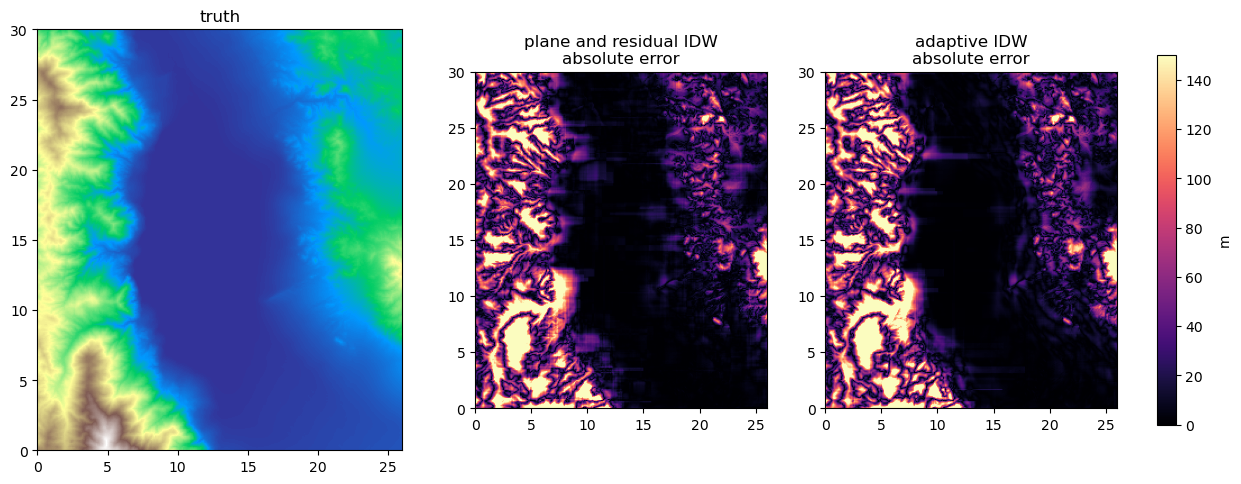

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(truth.reshape(shape), origin="lower", extent=extent, cmap="terrain")
axes[0].set_title("truth")
for ax, (name, estimate) in zip(axes[1:], maps.items()):
    im = ax.imshow(np.abs(estimate - truth).reshape(shape), origin="lower", extent=extent, cmap="magma",
                   vmin=0, vmax=150)
    ax.set_title(f"{name}\nabsolute error")
fig.colorbar(im, ax=axes[1:], shrink=0.8, label="m")
plt.show()

Both decoders reach their knee at fine partitions, with errors of the same order. The new decoder
does better by about a metre, by its leave-one-out error as against the truth, a difference small next
to the errors themselves. Their errors gather in the same places, the crests and the
steep slopes of the Wassuk Range, while the lake costs neither of them anything. The new decoder's
search is the faster here, since the adaptive IDW fits an anisotropy in every cell, even though it runs
on every core while ours runs on one.

### The move to C++

A decoder written in Python runs one cell at a time, since Python functions hold the interpreter lock,
so the session settings `parallel` and `num_threads` do not speed it up. It also receives no seed, so a
decoder that draws random numbers cannot be reproduced. A decoder meant to stay in the library, to run
on every core or to draw at random is written in C++, where `estimation`, `post_creation` and `loo`
become the methods of a class
([Writing a decoder in C++](https://spatialize.readthedocs.io/en/latest/development/cpp_decoders.html)).

## Pitfalls

- **A fit stored in `params` with the derived leave-one-out.** The derived version reuses the fit of
  the whole cell, so the held-out datum helped fit its own prediction. Write `loo`, or fit inside
  `estimation`.
- **Too few data for the model.** A plane through three data, or through data nearly on a line,
  extrapolates wildly across the cell. A first version of ours, which fitted a plane to any three
  data, gave a mean error of more than 600 km at `alpha` = 0.95. Give every model a minimum of data and a fallback.
- **Division by zero under numba.** Compiled code raises `ZeroDivisionError` where NumPy would return an infinity, stopping the estimation. Test the denominators.
- **Types under numba.** The arrays arrive as float32. A matrix product between float32 and float64
  arrays does not compile, so convert before multiplying.
- **The wrong number of values.** Each function returns one value per query, or one per datum for
  `loo`. Any other length raises an error naming the function.
- **Random numbers.** A decoder that draws gives different members on every run, and searches that do
  not repeat. Keep Python decoders deterministic.

## Try it yourself

1. Lower the minimum of data for a plane from six to three, and watch the error at `alpha` = 0.98.
2. Raise the exponent of the residual weighting from 2 to 3, and compare the leave-one-out error.
3. Run the plane with residual weighting on Voronoi partitions (`p_process="voronoi"`).
4. Fit a quadratic surface instead of a plane, with a larger minimum of data.

## Next

- *Encoders and decoders*, for the built-in decoders and what each assumes.
- *Choosing an ensemble with the Pareto search*, for the search used to choose `alpha`.
- *The probabilistic decoders*, for decoders that draw, written in C++.
- The documentation's [Writing a decoder in Python](https://spatialize.readthedocs.io/en/latest/development/python_decoders.html)
  and [Writing a decoder in C++](https://spatialize.readthedocs.io/en/latest/development/cpp_decoders.html)
  (developer guide).